In [10]:
import math
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from PIL import Image, ImageDraw

ERP_PATH = Path('./dataset/studio_small_09_1k.hdr')
NUM_SAMPLES = 4096
OUTPUT_PATH = Path('./outputs/studio_small_09_fibonacci.npz')
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [2]:
def fibonacci_directions(num_samples, device, dtype):
    """Return unit directions [N, 3] ordered from +Y toward -Y."""
    if not isinstance(num_samples, int) or isinstance(num_samples, bool) or num_samples < 1:
        raise ValueError('num_samples must be a positive integer')

    # Keep the longitude phase accurate before casting to the image dtype.
    index = torch.arange(num_samples, device=device, dtype=torch.float64)
    y = 1 - 2 * (index + 0.5) / num_samples
    radius = torch.sqrt((1 - y) * (1 + y))
    golden_angle = math.pi * (3 - math.sqrt(5))
    theta = torch.remainder(index * golden_angle, 2 * math.pi)
    directions = torch.stack((radius * theta.sin(), y, radius * theta.cos()), dim=-1)
    return directions.to(dtype=dtype)


def directions_to_erp_uv(directions):
    """Map unit directions to ERP coordinates measured from the image edges."""
    x, y, z = directions.unbind(dim=-1)
    u = torch.atan2(x, z) / (2 * math.pi) + 0.5
    v = 0.5 - torch.asin(y.clamp(-1, 1)) / math.pi
    return u, v


def erp_to_fibonacci(erp, num_samples):
    """Sample ERP [B, C, H, 2H] and return directions [N, 3] and values [B, N, C]."""
    if erp.ndim != 4:
        raise ValueError('Expected ERP shape [B, C, H, W]')
    if erp.dtype not in (torch.float32, torch.float64):
        raise TypeError('Use float32 or float64 for ERP values')
    batch, channels, height, width = erp.shape
    if min(batch, channels) < 1 or height < 2 or width != 2 * height:
        raise ValueError(f'Expected a nonempty complete 2:1 ERP, got {tuple(erp.shape)}')

    directions = fibonacci_directions(num_samples, erp.device, erp.dtype)
    u, v = directions_to_erp_uv(directions)

    # Sample longitude periodically by adding the opposite column at each edge.
    padded = torch.cat((erp[..., -1:], erp, erp[..., :1]), dim=-1)
    grid_x = 2 * (u * width + 1) / (width + 2) - 1
    grid_y = 2 * v - 1
    grid = torch.stack((grid_x, grid_y), dim=-1).reshape(1, 1, num_samples, 2)
    grid = grid.expand(batch, -1, -1, -1)
    sampled = F.grid_sample(
        padded, grid, mode='bilinear', padding_mode='border', align_corners=False,
    )
    return directions, sampled.squeeze(2).transpose(1, 2).contiguous()

In [7]:
bgr = cv2.imread(str(ERP_PATH), cv2.IMREAD_UNCHANGED)
if bgr is None:
    raise FileNotFoundError(f'Cannot read HDR image: {ERP_PATH.resolve()}')
if bgr.dtype != np.float32 or bgr.ndim != 3 or bgr.shape[2] != 3:
    raise ValueError('Expected a 3-channel float32 HDR image')

pixels = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
if not np.isfinite(pixels).all():
    raise ValueError('HDR contains non-finite values')

erp = torch.from_numpy(pixels).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
directions, rgb = erp_to_fibonacci(erp, NUM_SAMPLES)

print('ERP:', tuple(erp.shape), 'device:', erp.device)
print('Directions:', tuple(directions.shape), 'RGB:', tuple(rgb.shape))
print('Sampled HDR range:', (rgb.min().item(), rgb.max().item()))

ERP: (1, 3, 512, 1024) device: cuda:0
Directions: (32768, 3) RGB: (1, 32768, 3)
Sampled HDR range: (0.0010430291295051575, 325.7798767089844)


In [8]:
rgb_values = rgb.detach().cpu().numpy()
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(OUTPUT_PATH, directions=directions.cpu().numpy(), rgb=rgb_values)
print('Saved:', OUTPUT_PATH.resolve())

Saved: E:\model\erpProcess\outputs\studio_small_09_fibonacci.npz


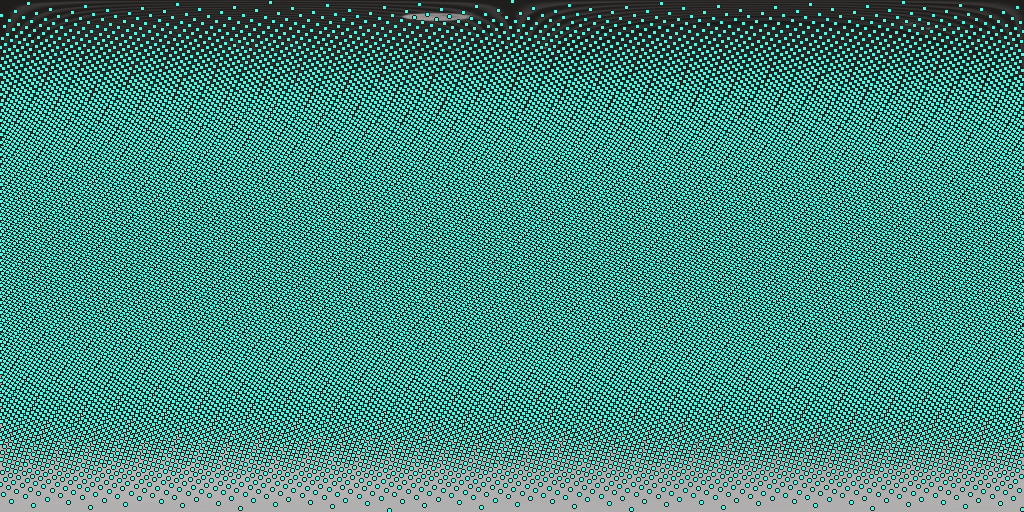

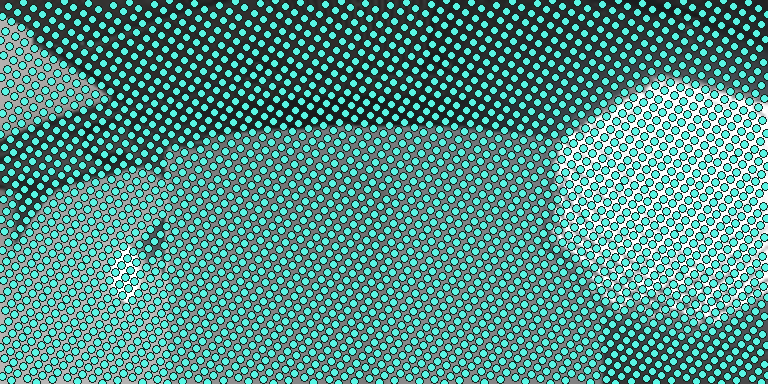

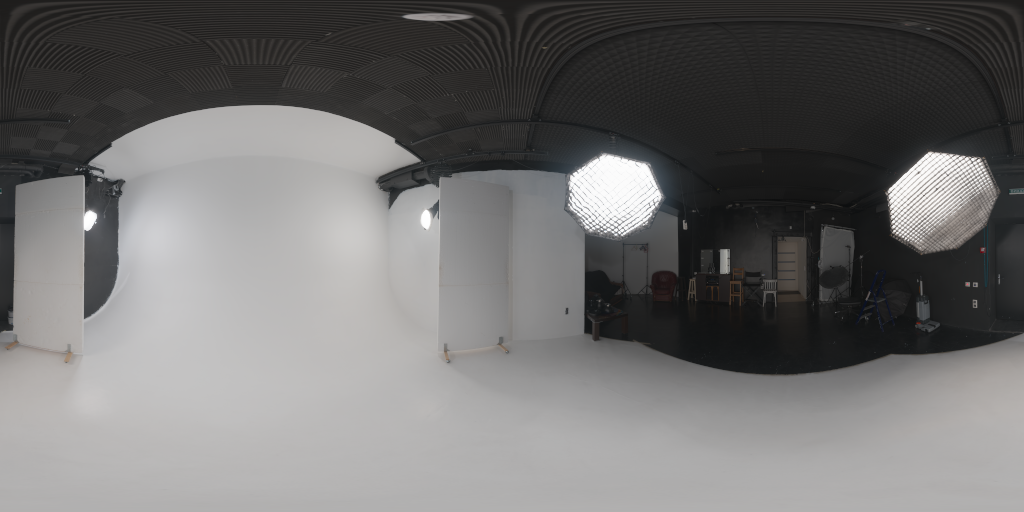

In [9]:
def hdr_preview(rgb):
    """Apply the same preview tone mapping used by cubefromerp.ipynb."""
    rgb = np.maximum(rgb, 0)
    mapped = (rgb / (1 + rgb)) ** (1 / 2.2)
    return np.rint(mapped * 255).astype(np.uint8)


def draw_sample_positions(image, positions, radius):
    draw = ImageDraw.Draw(image)
    for x, y in positions:
        column, row = math.floor(x), math.floor(y)
        draw.ellipse(
            (column - radius, row - radius, column + radius, row + radius),
            fill='#58F4E3', outline='#102923',
        )


erp_preview = Image.fromarray(hdr_preview(pixels)).resize((1024, 512), Image.Resampling.LANCZOS)
preview_width, preview_height = erp_preview.size
u, v = directions_to_erp_uv(directions)
uv = torch.stack((u.remainder(1), v), dim=-1).detach().cpu().numpy()
positions = uv * np.asarray(erp_preview.size, dtype=uv.dtype)

# Mark the central longitude band from the equator up to 45 degrees north.
left, right = 3 * preview_width // 8, 5 * preview_width // 8
top, bottom = preview_height // 4, preview_height // 2
zoom_box = (left, top, right, bottom)
overview = erp_preview.copy()
ImageDraw.Draw(overview).rectangle((left, top, right - 1, bottom - 1), outline='#FFC85F', width=3)
draw_sample_positions(overview, positions, radius=2)

zoom_scale = 3
zoom_size = ((right - left) * zoom_scale, (bottom - top) * zoom_scale)
zoom_preview = erp_preview.crop(zoom_box).resize(zoom_size, Image.Resampling.LANCZOS)
columns, rows = positions.T
visible = (left <= columns) & (columns < right) & (top <= rows) & (rows < bottom)
zoom_positions = (positions[visible] - (left, top)) * zoom_scale
draw_sample_positions(zoom_preview, zoom_positions, radius=4)

display(overview)
display(zoom_preview)
display( erp_preview)